# 과제 A — YOLO 서비스 노트북
이미지 경로를 바꿔 실행하면 **원본 · 박스(detection) · 마스크(segmentation)** 와 JSON을 확인합니다.

- 모델: `yolo26n.pt`(박스), `yolo26n-seg.pt`(마스크) — COCO 80 클래스
- 설정: `imgsz=640`, `device=cpu`, `conf=0.25 / 0.50`
- 실행 위치: 로컬 PC(Windows, CPU). 커널은 저장소의 `.venv-yolo` 를 사용

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd()/'yolo').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT/'yolo'))
import cv2, matplotlib.pyplot as plt
import yolo_core as yc
print('관찰 가능한 클래스 수:', len(yc.load_model(yc.DET_WEIGHTS).names))

관찰 가능한 클래스 수: 80


## 1) 입력 사진 지정 — 여기만 바꾸면 됩니다
관찰 대상 클래스: `person`, `bus`(버스 사진), `laptop`, `cup`, `dining table`(책상 사진)

In [2]:
IMAGE = ROOT/'input/bus.jpg'   # 예: ROOT/'input/desk-objects.jpg' 또는 내 사진 경로
CONFS = (0.25, 0.50)

## 2) 원본 · 박스 · 마스크 (두 임계값)

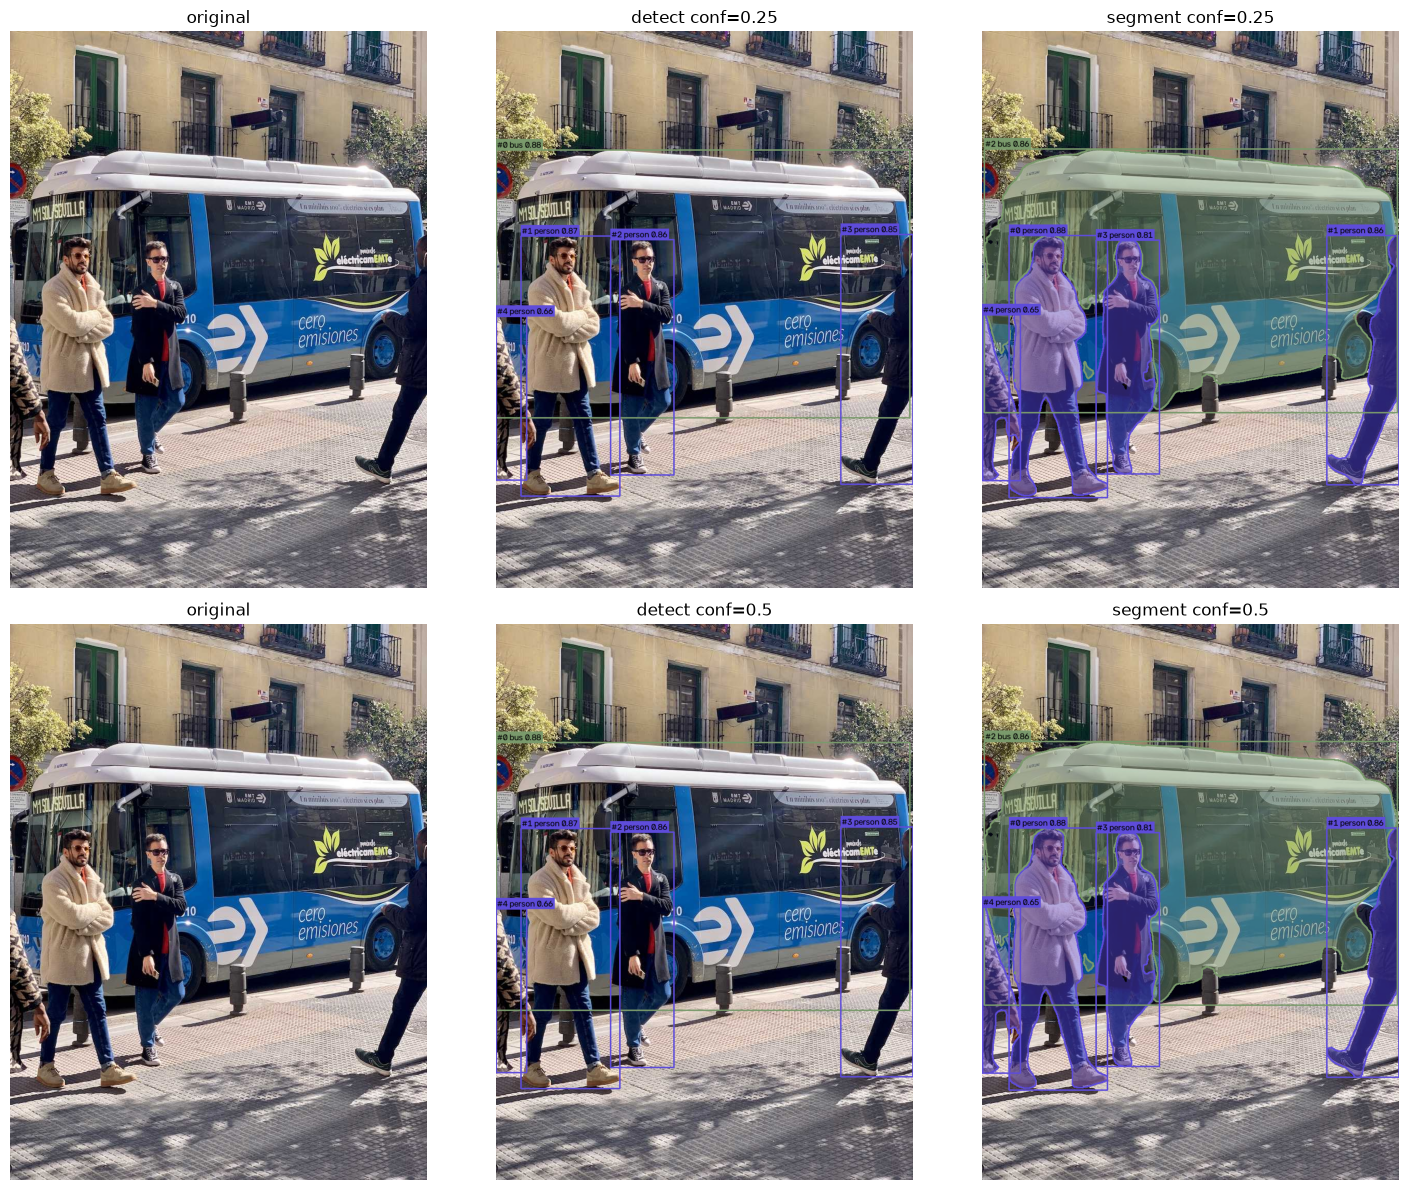

In [3]:
img = cv2.imread(str(IMAGE))
res = {}
fig, ax = plt.subplots(len(CONFS), 3, figsize=(15, 6*len(CONFS)))
for r, c in enumerate(CONFS):
    det, seg = yc.detect(IMAGE, c), yc.segment(IMAGE, c)
    res[c] = (det, seg)
    for k, (im, t) in enumerate([(img, 'original'), (yc.draw_boxes(img, det['detections']), f'detect conf={c}'),
                                 (yc.draw_masks(img, seg['instances'], seg['_masks']), f'segment conf={c}')]):
        ax[r, k].imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax[r, k].set_title(t); ax[r, k].axis('off')
plt.tight_layout(); plt.show()

## 3) JSON — 화면의 박스 하나를 좌표와 연결해 보기

In [4]:
for c in CONFS:
    print(f'--- conf={c}')
    for d in res[c][0]['detections']:
        print(d)


--- conf=0.25
{'id': 0, 'class_id': 5, 'class_name': 'bus', 'confidence': 0.8806, 'box_xyxy': [0.0, 230.5, 803.2, 750.7]}
{'id': 1, 'class_id': 0, 'class_name': 'person', 'confidence': 0.872, 'box_xyxy': [48.6, 397.7, 240.3, 902.4]}
{'id': 2, 'class_id': 0, 'class_name': 'person', 'confidence': 0.8608, 'box_xyxy': [222.9, 404.8, 345.5, 861.0]}
{'id': 3, 'class_id': 0, 'class_name': 'person', 'confidence': 0.8462, 'box_xyxy': [669.6, 394.5, 809.9, 879.4]}
{'id': 4, 'class_id': 0, 'class_name': 'person', 'confidence': 0.6562, 'box_xyxy': [0.2, 553.0, 59.7, 871.3]}
--- conf=0.5
{'id': 0, 'class_id': 5, 'class_name': 'bus', 'confidence': 0.8806, 'box_xyxy': [0.0, 230.5, 803.2, 750.7]}
{'id': 1, 'class_id': 0, 'class_name': 'person', 'confidence': 0.872, 'box_xyxy': [48.6, 397.7, 240.3, 902.4]}
{'id': 2, 'class_id': 0, 'class_name': 'person', 'confidence': 0.8608, 'box_xyxy': [222.9, 404.8, 345.5, 861.0]}
{'id': 3, 'class_id': 0, 'class_name': 'person', 'confidence': 0.8462, 'box_xyxy': [66

In [5]:
print(json.dumps(yc.public(res[0.25][1])['instances'], ensure_ascii=False, indent=1)[:2000])

[
 {
  "id": 0,
  "class_id": 0,
  "class_name": "person",
  "confidence": 0.877,
  "box_xyxy": [
   52.8,
   396.7,
   243.4,
   905.9
  ],
  "mask_area_px": 49302,
  "box_area_px": 97049,
  "mask_to_box_ratio": 0.508
 },
 {
  "id": 1,
  "class_id": 0,
  "class_name": "person",
  "confidence": 0.8632,
  "box_xyxy": [
   669.2,
   396.2,
   809.9,
   880.3
  ],
  "mask_area_px": 21311,
  "box_area_px": 68096,
  "mask_to_box_ratio": 0.313
 },
 {
  "id": 2,
  "class_id": 5,
  "class_name": "bus",
  "confidence": 0.8555,
  "box_xyxy": [
   4.8,
   228.5,
   806.6,
   740.2
  ],
  "mask_area_px": 255375,
  "box_area_px": 410221,
  "mask_to_box_ratio": 0.623
 },
 {
  "id": 3,
  "class_id": 0,
  "class_name": "person",
  "confidence": 0.8106,
  "box_xyxy": [
   221.1,
   405.4,
   344.5,
   859.4
  ],
  "mask_area_px": 33411,
  "box_area_px": 56022,
  "mask_to_box_ratio": 0.596
 },
 {
  "id": 4,
  "class_id": 0,
  "class_name": "person",
  "confidence": 0.6484,
  "box_xyxy": [
   0.5,
   550

## 4) 임계값 사이(0.25~0.50)에 있던 후보 — 모델 원출력을 낮은 임계값으로 확인
두 결과가 같다면, 점수 0.25~0.50 사이 후보가 없었다는 뜻입니다. conf=0.05로 원출력을 보면 무엇이 걸러졌는지 알 수 있습니다.

In [6]:
for w in (yc.DET_WEIGHTS, yc.SEG_WEIGHTS):
    r = yc.load_model(w).predict(str(IMAGE), imgsz=640, conf=0.05, device='cpu', verbose=False)[0]
    print(w, [(r.names[int(b.cls)], round(float(b.conf), 3)) for b in r.boxes])

yolo26n.pt [('bus', 0.881), ('person', 0.872), ('person', 0.861), ('person', 0.846), ('person', 0.656), ('stop sign', 0.128), ('handbag', 0.076), ('skateboard', 0.071), ('handbag', 0.053)]
yolo26n-seg.pt [('person', 0.877), ('person', 0.863), ('bus', 0.856), ('person', 0.811), ('person', 0.648), ('bus', 0.059), ('handbag', 0.058)]


## 5) 저장 — 배치 스크립트로 outputs/yolo/ 에 이미지·JSON·마스크·manifest 저장
내 사진을 추가하려면 `yolo/run_yolo.py input/bus.jpg input/desk-objects.jpg input/내사진.jpg` 처럼 경로를 넘깁니다.

In [7]:
import subprocess
print(subprocess.run([sys.executable, str(ROOT/'yolo/run_yolo.py')], cwd=ROOT, capture_output=True, text=True, encoding='utf-8').stdout[-1500:])

saved -> C:\AIAgent\AIImage\outputs\yolo
{'input': 'input\\bus.jpg', 'by_conf': {'0.25': {'detect_counts': {'bus': 1, 'person': 4}, 'segment_counts': {'person': 4, 'bus': 1}}, '0.50': {'detect_counts': {'bus': 1, 'person': 4}, 'segment_counts': {'person': 4, 'bus': 1}}}, 'threshold_diff': {'detect_dropped': 0, 'segment_dropped': 0}}
{'input': 'input\\desk-objects.jpg', 'by_conf': {'0.25': {'detect_counts': {'cup': 1, 'laptop': 1}, 'segment_counts': {'cup': 1, 'laptop': 1, 'dining table': 1}}, '0.50': {'detect_counts': {'cup': 1, 'laptop': 1}, 'segment_counts': {'cup': 1, 'laptop': 1}}}, 'threshold_diff': {'detect_dropped': 0, 'segment_dropped': 1}}

